共同样本区间: 2024-11-19 ~ 2026-10-29, 共 471 个交易日

==================== 表1: 平稳性检测(ADF) ====================
序列  水平DF  水平P值  一阶差分DF  一阶差分P值
lnP_RB -2.08  0.25  -23.04     0.0
lnP_LG -1.97  0.30  -21.04     0.0

==================== 表2: 格兰杰因果检验(日对数收益, F统计量/P值) ====================
LG -> RB (原木对螺纹钢)  lag1: F=1.15(p=0.28) | lag2: F=0.78(p=0.46) | lag3: F=1.26(p=0.29) | lag4: F=1.06(p=0.38) | lag5: F=0.99(p=0.42)
RB -> LG (螺纹钢对原木)  lag1: F=3.81(p=0.05) | lag2: F=2.42(p=0.09) | lag3: F=1.95(p=0.12) | lag4: F=1.70(p=0.15) | lag5: F=1.36(p=0.24)

==================== 表3: 协整回归 ====================
alpha = 3.1388, beta = 0.7363, R^2 = 0.458
残差ADF: DF = -3.76, P = 0.003
Engle-Granger协整检验(coint): t = -3.76, P = 0.015


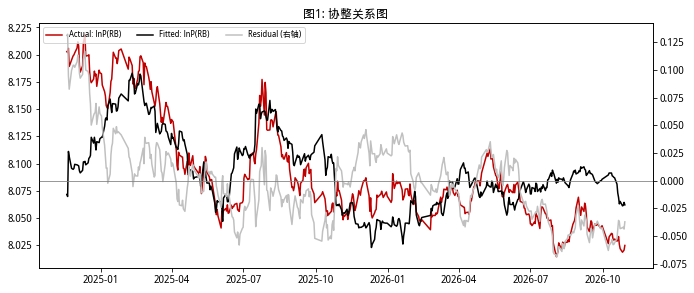


==================== 等价值配比示例 ====================
2025-11-07: 1手螺纹钢=30340元, 1手原木=70065元, 1手原木≈2.31手螺纹钢, 最小整数比 螺纹钢:原木 = 3:1, 放大后 30:10 手


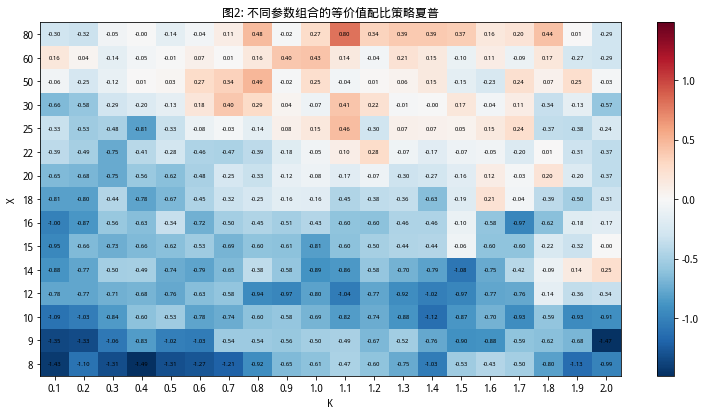


遍历得到的最优参数(样本内): X=80, K=1.1, 夏普=0.80  (研报最优: X=25, K=0.8, 该组合夏普=-0.14)

==================== 表4: 螺纹钢与原木套利策略回测表现 (X=25, K=0.8) ====================
                              数值
Sortino比率                  -0.20
信号触发占比                    55.48%
信息比率                       -0.14
区间收益                      -2.56%
回测区间       2024-11-19~2026-10-29
夏普比率                       -0.14
年化收益                      -1.38%
开仓次数                         247
开仓胜率                      46.96%
最大回撤                     -10.81%


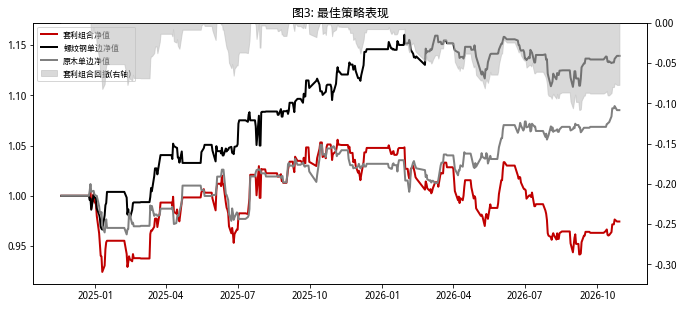

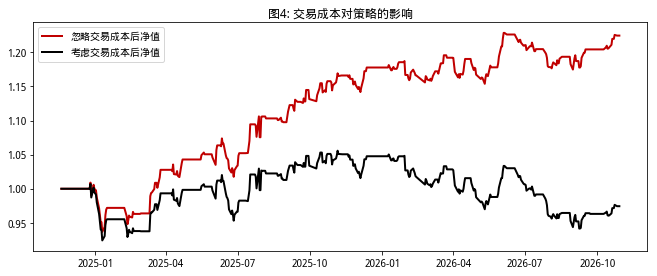


信号触发占比: 55.48% ; 开仓次数: 247 ; 累计手续费占本金: 25.01%
注: 协整回归系数使用全样本OLS(与研报一致)，参数遍历/最优参数均为样本内结果，存在前视/过拟合风险，仅用于复现。


In [1]:
# -*- coding: utf-8 -*-
"""
复现研报：《创新跨品种套利策略：原木与螺纹钢（下）》(华泰期货, 2025-09-01)
运行环境：聚宽研究环境 (Python 3.6.7 / numpy 1.19.5 / pandas 0.23.4 / scipy 1.2.0)
说明：
  * 全程不写磁盘：数据直接使用，结果直接 print / plt.show
  * 写法兼容旧版本（不使用 .to_numpy()、不使用 pandas>=0.24 的新接口）
  * statsmodels 若不可用，则仅跳过 ADF / 格兰杰 / 协整检验的统计表，不影响策略回测
流程：
  1. 取数：螺纹钢 RB / 原木 LG 主力连续合约收盘价 + 用主力合约换月构造"复权收盘价"
  2. 平稳性检验(表1)、格兰杰因果(表2)、协整回归(表3)、协整关系图(图1)
  3. 残差 z 分数信号：收盘后出信号 -> T+1 收盘开仓 -> T+2 收盘平仓，手续费 0.03%
  4. 等价值配比手数(最小整数比 + 资金放大)
  5. 参数遍历 X x K 的夏普热力图(图2)、最佳策略(图3)、成本影响(图4)、回测表现(表4)
"""
import datetime
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from jqdata import *

try:
    from statsmodels.tsa.stattools import adfuller, grangercausalitytests, coint
    HAS_SM = True
except Exception as _e:
    HAS_SM = False
    print("statsmodels 不可用，将跳过统计检验表:", _e)

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'WenQuanYi Micro Hei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ============================== 参数区 ==============================
START = '2024-01-01'
END = '2026-12-20'
RB_MAIN = 'RB9999.XSGE'      # 螺纹钢主力连续
LG_MAIN = 'LG9999.XDCE'      # 原木主力连续(2024-11-18 上市)
RB_PREFIX = 'RB'
LG_PREFIX = 'LG'
MULT_RB = 10                 # 螺纹钢合约乘数 (吨/手)
MULT_LG = 90                 # 原木合约乘数 (立方米/手)
FEE = 0.0003                 # 手续费 0.03% (单边, 按名义价值, 开平各收一次)
CAPITAL = 1000000.0          # 回测本金，净值 = 1 + 累计盈亏/CAPITAL
LEVERAGE = 1.0               # 单腿名义价值 ≈ CAPITAL*LEVERAGE (用于确定放大倍数)
RATIO_MODE = 'ceil'          # 'ceil': 与研报一致(2.36 -> 3:1)；'round': 四舍五入(2.36 -> 2:1)
USE_DOMINANT_ADJ = True      # True: 用主力合约换月收益拼接复权价；False: 直接用9999连续收盘价
BEST_X, BEST_K = 25, 0.8     # 研报最优参数(仅用于对照打印)
X_LIST = [8, 9, 10, 12, 14, 15, 16, 18, 20, 22, 25, 30, 50, 60, 80]
K_LIST = [round(0.1 * i, 1) for i in range(1, 21)]   # 0.1 ~ 2.0
GC_MAXLAG = 5                # 格兰杰因果最大滞后阶数

# ============================== 1. 取数 ==============================
today = datetime.date.today()
END_EFF = min(datetime.datetime.strptime(END, '%Y-%m-%d').date(), today).strftime('%Y-%m-%d')


def get_close(code, start, end):
    df = get_price(code, start_date=start, end_date=end, frequency='daily',
                   fields=['close'], skip_paused=True, panel=False)
    s = df['close'].astype(float)
    s.index = pd.to_datetime(s.index)
    return s


rb_main = get_close(RB_MAIN, START, END_EFF)
lg_main = get_close(LG_MAIN, START, END_EFF)
common = rb_main.index.intersection(lg_main.index)
rb_main = rb_main.loc[common].dropna()
lg_main = lg_main.loc[common].dropna()
common = rb_main.index.intersection(lg_main.index)
rb_main, lg_main = rb_main.loc[common], lg_main.loc[common]
print("共同样本区间: %s ~ %s, 共 %d 个交易日" % (common[0].date(), common[-1].date(), len(common)))


def build_adj_close(prefix, main_close):
    """用'前一日主力合约'计算当日收益，拼接得到无换月跳空的复权收盘价(以最新价为锚)"""
    dates = main_close.index
    dom = []
    for d in dates:
        try:
            c = get_dominant_future(prefix, d.date())
        except Exception:
            c = None
        dom.append(c if c else None)
    dom = pd.Series(dom, index=dates).ffill().bfill()
    px = {}
    for c in dom.unique():
        try:
            s = get_price(c, start_date=dates[0].strftime('%Y-%m-%d'),
                          end_date=dates[-1].strftime('%Y-%m-%d'), frequency='daily',
                          fields=['close'], skip_paused=False, panel=False)['close']
            s.index = pd.to_datetime(s.index)
            px[c] = s
        except Exception:
            px[c] = pd.Series(dtype=float)
    r = main_close.pct_change().fillna(0.0).values.copy()   # 取不到时退回9999收益
    for i in range(1, len(dates)):
        s = px.get(dom.iloc[i - 1])
        if s is None or len(s) == 0:
            continue
        try:
            p1 = s.loc[dates[i]]
            p0 = s.loc[dates[i - 1]]
        except KeyError:
            continue
        if np.isfinite(p1) and np.isfinite(p0) and p0 > 0 and p1 > 0:
            r[i] = p1 / p0 - 1.0
    cum = np.cumprod(1.0 + r)
    adj = cum / cum[-1] * main_close.iloc[-1]
    return pd.Series(adj, index=dates), pd.Series(r, index=dates)


if USE_DOMINANT_ADJ:
    rb_adj, rb_ret = build_adj_close(RB_PREFIX, rb_main)
    lg_adj, lg_ret = build_adj_close(LG_PREFIX, lg_main)
else:
    rb_adj, lg_adj = rb_main.copy(), lg_main.copy()
    rb_ret = rb_adj.pct_change().fillna(0.0)
    lg_ret = lg_adj.pct_change().fillna(0.0)

lnrb = np.log(rb_adj)
lnlg = np.log(lg_adj)
r_rb = lnrb.diff()
r_lg = lnlg.diff()

# ============================== 2. 实证研究 ==============================
print("\n" + "=" * 20 + " 表1: 平稳性检测(ADF) " + "=" * 20)
if HAS_SM:
    rows = []
    for name, s in [('lnP_RB', lnrb), ('lnP_LG', lnlg)]:
        a = adfuller(s.dropna().values, regression='c', autolag='AIC')
        b = adfuller(s.diff().dropna().values, regression='c', autolag='AIC')
        rows.append([name, round(a[0], 2), round(a[1], 2), round(b[0], 2), round(b[1], 2)])
    print(pd.DataFrame(rows, columns=['序列', '水平DF', '水平P值', '一阶差分DF', '一阶差分P值']).to_string(index=False))

    print("\n" + "=" * 20 + " 表2: 格兰杰因果检验(日对数收益, F统计量/P值) " + "=" * 20)
    gdata = pd.concat([r_rb, r_lg], axis=1).dropna()
    gdata.columns = ['RB', 'LG']
    for tag, cols in [('LG -> RB (原木对螺纹钢)', ['RB', 'LG']), ('RB -> LG (螺纹钢对原木)', ['LG', 'RB'])]:
        try:
            gc = grangercausalitytests(gdata[cols].values, maxlag=GC_MAXLAG, verbose=False)
        except TypeError:
            gc = grangercausalitytests(gdata[cols].values, maxlag=GC_MAXLAG)
        out = []
        for lag in range(1, GC_MAXLAG + 1):
            f, p = gc[lag][0]['ssr_ftest'][:2]
            out.append("lag%d: F=%.2f(p=%.2f)" % (lag, f, p))
        print(tag + "  " + " | ".join(out))
else:
    print("(跳过)")

# ---- 协整回归 lnP_RB = a + b*lnP_LG + e (全样本OLS，与研报一致) ----
beta, alpha = np.polyfit(lnlg.values, lnrb.values, 1)
fitted = alpha + beta * lnlg
resid = lnrb - fitted
r2 = 1.0 - (resid ** 2).sum() / ((lnrb - lnrb.mean()) ** 2).sum()
print("\n" + "=" * 20 + " 表3: 协整回归 " + "=" * 20)
print("alpha = %.4f, beta = %.4f, R^2 = %.3f" % (alpha, beta, r2))
if HAS_SM:
    a = adfuller(resid.values, regression='c', autolag='AIC')
    print("残差ADF: DF = %.2f, P = %.3f" % (a[0], a[1]))
    try:
        c = coint(lnrb.values, lnlg.values)
        print("Engle-Granger协整检验(coint): t = %.2f, P = %.3f" % (c[0], c[1]))
    except Exception as e:
        print("coint 失败:", e)

# ---- 图1 协整关系图 ----
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(lnrb.index, lnrb.values, color='#C00000', label='Actual: lnP(RB)')
ax.plot(lnrb.index, fitted.values, color='black', label='Fitted: lnP(RB)')
ax2 = ax.twinx()
ax2.plot(resid.index, resid.values, color='silver', label='Residual (右轴)')
ax2.axhline(0, color='gray', lw=0.8)
l1, n1 = ax.get_legend_handles_labels()
l2, n2 = ax2.get_legend_handles_labels()
ax.legend(l1 + l2, n1 + n2, loc='upper left', ncol=3, fontsize=8)
ax.set_title('图1: 协整关系图')
plt.show()

# ============================== 3. 策略构建 ==============================
nv_rb = rb_main * MULT_RB          # 单手名义价值(用真实收盘价)
nv_lg = lg_main * MULT_LG
ratio = nv_lg / nv_rb              # 1手原木 ≈ ratio 手螺纹钢
if RATIO_MODE == 'ceil':
    rfun = np.ceil
else:
    rfun = np.round
a_rb = np.where(ratio >= 1, np.maximum(1, rfun(ratio)), 1.0)           # 最小整数比
b_lg = np.where(ratio >= 1, 1.0, np.maximum(1, rfun(1.0 / ratio)))
leg_max = np.maximum(a_rb * nv_rb.values, b_lg * nv_lg.values)
mult = np.maximum(1.0, np.floor(CAPITAL * LEVERAGE / leg_max))         # 资金放大倍数
lots_rb = pd.Series(a_rb * mult, index=common)
lots_lg = pd.Series(b_lg * mult, index=common)
N_rb = lots_rb * nv_rb             # 每腿名义金额
N_lg = lots_lg * nv_lg

ex = common[min(len(common) - 1, len(common) // 2)]
print("\n" + "=" * 20 + " 等价值配比示例 " + "=" * 20)
print("%s: 1手螺纹钢=%.0f元, 1手原木=%.0f元, 1手原木≈%.2f手螺纹钢, 最小整数比 螺纹钢:原木 = %d:%d, 放大后 %d:%d 手"
      % (ex.date(), nv_rb[ex], nv_lg[ex], ratio[ex], a_rb[len(common) // 2], b_lg[len(common) // 2],
         lots_rb[ex], lots_lg[ex]))


def backtest(X, K, fee=FEE):
    """返回 dict: 日收益(净)、分腿盈亏、信号占比、逐笔胜率等"""
    m = resid.rolling(X).mean()
    s = resid.rolling(X).std()
    dev = resid - m
    sig = pd.Series(0.0, index=common)
    sig[dev > K * s] = -1.0      # 残差偏高: 空螺纹钢、多原木
    sig[dev < -K * s] = 1.0      # 残差偏低: 多螺纹钢、空原木
    valid_sig = s.notnull()
    sig_ratio = (sig[valid_sig] != 0).mean() if valid_sig.sum() > 0 else np.nan

    e = sig.shift(1).fillna(0.0)                 # T+1 收盘开仓(d)，T+2 收盘平仓(d+1)
    nxt_rb = rb_ret.shift(-1)
    nxt_lg = lg_ret.shift(-1)
    ok = nxt_rb.notnull() & nxt_lg.notnull()
    e = e.where(ok, 0.0)
    nxt_rb = nxt_rb.fillna(0.0)
    nxt_lg = nxt_lg.fillna(0.0)

    pnl_rb = e * N_rb * nxt_rb
    pnl_lg = -e * N_lg * nxt_lg
    cost = e.abs() * fee * (N_rb + N_lg + N_rb * (1 + nxt_rb) + N_lg * (1 + nxt_lg))
    trade_net = pnl_rb + pnl_lg - cost           # 逐笔净盈亏(记在开仓日)
    # 盈亏在平仓日(d+1)实现
    day_rb = pnl_rb.shift(1).fillna(0.0)
    day_lg = pnl_lg.shift(1).fillna(0.0)
    day_cost = cost.shift(1).fillna(0.0)
    day_net = day_rb + day_lg - day_cost
    ntr = int((e != 0).sum())
    win = float((trade_net[e != 0] > 0).mean()) if ntr > 0 else np.nan
    return dict(ret=day_net / CAPITAL, rb=day_rb / CAPITAL, lg=day_lg / CAPITAL,
                cost=day_cost / CAPITAL, sig_ratio=sig_ratio, win=win, ntr=ntr, sig=sig)


def sharpe(ret):
    sd = ret.std()
    return ret.mean() / sd * np.sqrt(252) if sd > 0 else np.nan


def perf(res):
    ret = res['ret']
    nav = 1.0 + ret.cumsum()
    n = len(ret)
    tot = nav.iloc[-1] - 1.0
    ann = (1 + tot) ** (252.0 / n) - 1 if (1 + tot) > 0 else np.nan
    dd = nav / nav.cummax() - 1.0
    down = np.sqrt((np.minimum(ret.values, 0.0) ** 2).mean())
    sortino = ret.mean() / down * np.sqrt(252) if down > 0 else np.nan
    sh = sharpe(ret)
    return dict(回测区间='%s~%s' % (ret.index[0].date(), ret.index[-1].date()),
                区间收益='%.2f%%' % (tot * 100), 年化收益='%.2f%%' % (ann * 100),
                夏普比率='%.2f' % sh, Sortino比率='%.2f' % sortino,
                最大回撤='%.2f%%' % (dd.min() * 100), 信息比率='%.2f' % sh,
                开仓胜率='%.2f%%' % (res['win'] * 100), 信号触发占比='%.2f%%' % (res['sig_ratio'] * 100),
                开仓次数=res['ntr']), nav, dd


# ============================== 4. 参数遍历 ==============================
grid = pd.DataFrame(index=X_LIST, columns=K_LIST, dtype=float)
for X in X_LIST:
    for K in K_LIST:
        grid.loc[X, K] = sharpe(backtest(X, K)['ret'])

fig, ax = plt.subplots(figsize=(13, 6.5))
mat = grid.loc[X_LIST[::-1]].values.astype(float)       # X 大的在上
im = ax.imshow(mat, cmap='RdBu_r', aspect='auto',
               vmin=-np.nanmax(np.abs(mat)), vmax=np.nanmax(np.abs(mat)))
ax.set_xticks(range(len(K_LIST)))
ax.set_xticklabels(K_LIST)
ax.set_yticks(range(len(X_LIST)))
ax.set_yticklabels(X_LIST[::-1])
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        if np.isfinite(mat[i, j]):
            ax.text(j, i, '%.2f' % mat[i, j], ha='center', va='center', fontsize=6)
ax.set_xlabel('K')
ax.set_ylabel('X')
ax.set_title('图2: 不同参数组合的等价值配比策略夏普')
plt.colorbar(im)
plt.show()

stack = grid.stack()
bx, bk = stack.idxmax()
print("\n遍历得到的最优参数(样本内): X=%s, K=%s, 夏普=%.2f  (研报最优: X=%d, K=%.1f, 该组合夏普=%.2f)"
      % (bx, bk, stack.max(), BEST_X, BEST_K,
         grid.loc[BEST_X, BEST_K] if (BEST_X in grid.index and BEST_K in grid.columns) else np.nan))

# ============================== 5. 最佳策略 ==============================
# 与研报保持一致使用 X=25,K=0.8 ；如需使用本样本遍历出的最优参数，改为 USE_X, USE_K = bx, bk
USE_X, USE_K = BEST_X, BEST_K
res = backtest(USE_X, USE_K)
res_nc = backtest(USE_X, USE_K, fee=0.0)
stat, nav, dd = perf(res)

print("\n" + "=" * 20 + " 表4: 螺纹钢与原木套利策略回测表现 (X=%d, K=%.1f) " % (USE_X, USE_K) + "=" * 20)
print(pd.DataFrame([stat]).T.rename(columns={0: '数值'}).to_string())

nav_rb = 1.0 + res['rb'].cumsum()
nav_lg = 1.0 + res['lg'].cumsum()
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(nav.index, nav.values, color='#C00000', lw=2, label='套利组合净值')
ax.plot(nav_rb.index, nav_rb.values, color='black', lw=2, label='螺纹钢单边净值')
ax.plot(nav_lg.index, nav_lg.values, color='gray', lw=2, label='原木单边净值')
ax2 = ax.twinx()
ax2.fill_between(dd.index, dd.values, 0, color='silver', alpha=0.6, label='套利组合回撤(右轴)')
ax2.set_ylim(min(dd.min() * 3, -0.01), 0)
l1, n1 = ax.get_legend_handles_labels()
l2, n2 = ax2.get_legend_handles_labels()
ax.legend(l1 + l2, n1 + n2, loc='upper left', fontsize=8)
ax.set_title('图3: 最佳策略表现')
plt.show()

nav_nc = 1.0 + res_nc['ret'].cumsum()
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(nav_nc.index, nav_nc.values, color='#C00000', lw=2, label='忽略交易成本后净值')
ax.plot(nav.index, nav.values, color='black', lw=2, label='考虑交易成本后净值')
ax.legend(loc='upper left')
ax.set_title('图4: 交易成本对策略的影响')
plt.show()

print("\n信号触发占比: %.2f%% ; 开仓次数: %d ; 累计手续费占本金: %.2f%%"
      % (res['sig_ratio'] * 100, res['ntr'], res['cost'].sum() * 100))
print("注: 协整回归系数使用全样本OLS(与研报一致)，参数遍历/最优参数均为样本内结果，存在前视/过拟合风险，仅用于复现。")
